# PSD Computation from EDF Files

This notebook walks through the full pipeline for computing Power Spectral Densities (PSDs)
from EEG recordings stored as EDF files, using the `ebb` library and `openseize`.

**Pipeline overview:**
1. Load an EDF and inspect the raw signal
2. Understand what a PSD is and how Welch's method works
3. Compute a PSD on raw data
4. Apply artifact masks before computing
5. Compute state-specific PSDs (wake / NREM / REM)
6. Load and interpret results from `psds_channel_merged.pkl`
7. Plot group-level PSDs across animals

> **Set these paths before running:**

In [1]:
from pathlib import Path

# ── Edit these ──────────────────────────────────────────────────────────────
EDF_PATH     = Path("/media/matt/Data_A/leah/GUI_Test3/standard/ASR05_P106_91_29_ASO p3wks_2 days EEG_2022-03-02_10_23_55_PREPROCESSED.edf")
STATE_CSV    = Path("/media/matt/Data_A/leah/GUI_Test3/spindle_outputs/LFC_RSC/ASR05_P106_91_29_ASO_p3wks_2_days_EEG_2022-03-02_10_23_55_PREPROCESSED_SPINDLE_labels.csv")
MERGED_PKL   = Path("/media/matt/Data_A/leah/GUI_Test3/psd/psds_channel_merged.pkl")
# ────────────────────────────────────────────────────────────────────────────

FS = 250  # sampling rate (Hz)

In [26]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

from openseize.file_io import edf
from openseize import producer
from openseize.spectra.estimators import psd

from ebb import masking

plt.rcParams['figure.dpi'] = 110
CH_NAMES = ['LFC', 'RSC', 'LSC', 'EMG']  # channel labels

---
## 1. Load an EDF and inspect the raw signal

In [47]:
with edf.Reader(EDF_PATH) as reader:
    print("Shape (channels × samples):", reader.shape)
    print("Channels                  :", reader.header.names)
    print("Samples per record        :", reader.header.samples_per_record)
    print("Duration                  :", reader.shape[-1] / FS / 3600, "hours")
    
    # Load first 30 seconds for inspection
    reader.channels = [0, 1, 2]  # skip EMG for plotting
    data_30s = reader.read(start=0, stop=30 * FS)

Shape (channels × samples): (4, 5400000)
Channels                  : ['EEG EEG_1_SA-B', 'EEG EEG_2_SA-B', 'EEG EEG_3_SA-B', 'EEG EEG_4_SA-B']
Samples per record        : [250, 250, 250, 250]
Duration                  : 6.0 hours


In [ ]:
d

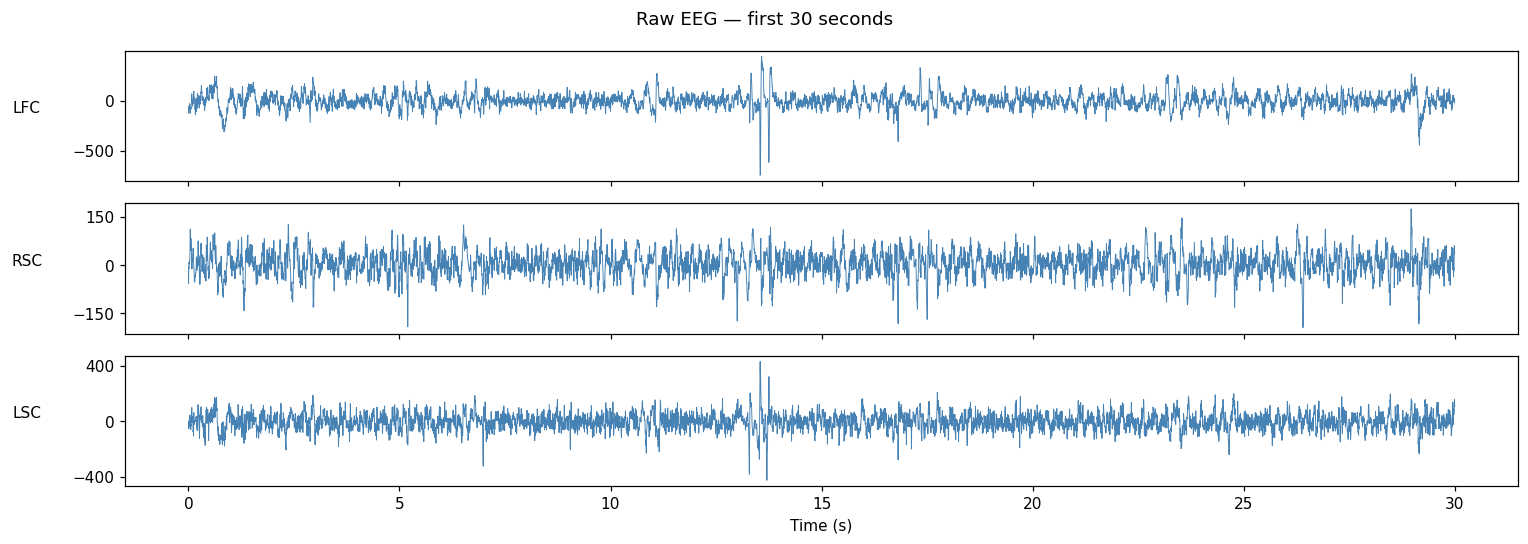

In [28]:
t = np.arange(data_30s.shape[-1]) / FS

fig, axes = plt.subplots(3, 1, figsize=(14, 5), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, data_30s[i], lw=0.6, color='steelblue')
    ax.set_ylabel(CH_NAMES[i], rotation=0, labelpad=30)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Raw EEG — first 30 seconds')
plt.tight_layout()
plt.show()

---
## 2. What is a PSD and how does Welch's method work?

A **Power Spectral Density** decomposes a signal into its constituent frequencies and
tells you how much *power* (variance) lives at each frequency.

**Welch's method** (the standard approach):
1. Divide the signal into overlapping windows
2. Apply a taper (Hann window) to each window to reduce spectral leakage
3. Compute the periodogram (FFT²) of each window
4. Average the periodograms → smoother, lower-variance estimate

Key parameter: **frequency resolution** = 1 / window_length
- Longer windows → finer frequency resolution, but fewer averages
- We use `resolution=0.5 Hz` → 2-second windows

The result has units of **V²/Hz** (power spectral *density*) — area under the curve between
two frequencies gives you the total power in that band.

---
## 3. Compute a basic PSD (no masking)

We use `openseize`'s `producer` to stream the EDF in chunks, avoiding loading the whole
file into memory at once.

In [29]:
with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0, 1, 2]  # LFC, RSC, LSC
    pro = producer(reader, chunksize=int(30e5), axis=-1)
    cnt, freqs, psds_raw = psd(pro, fs=FS, resolution=0.5, window='hann', overlap=0.5)

print(f"Frequency bins : {len(freqs)}  ({freqs[0]:.1f} – {freqs[-1]:.1f} Hz)")
print(f"PSD shape      : {psds_raw.shape}  (channels × freqs)")
print(f"Window count   : {cnt}")

Frequency bins : 251  (0.0 – 125.0 Hz)
PSD shape      : (3, 251)  (channels × freqs)
Window count   : 21599


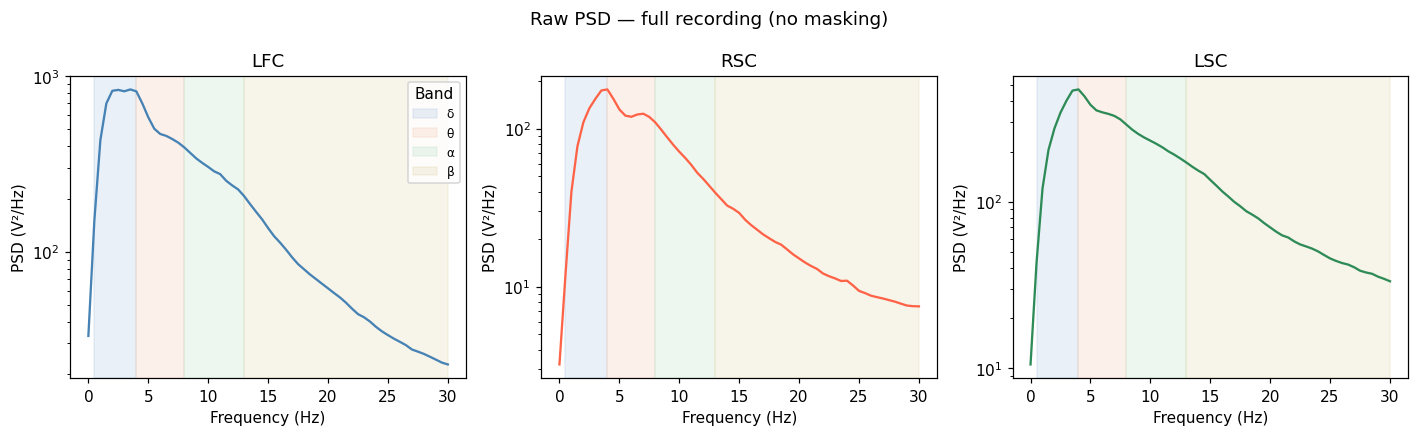

In [35]:
# Plot up to 30 Hz (EEG bands of interest)
freq_mask = freqs <= 30

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
colors = ['steelblue', 'tomato', 'seagreen']
for i, ax in enumerate(axes):
    ax.semilogy(freqs[freq_mask], psds_raw[i, freq_mask], color=colors[i], lw=1.5)
    ax.set_title(CH_NAMES[i])
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (V²/Hz)')
    # shade canonical EEG bands
    for band, (lo, hi, c) in {
        'δ': (0.5, 4,   '#aac4e0'),
        'θ': (4,   8,   '#f5c6b0'),
        'α': (8,   13,  '#b8e0c4'),
        'β': (13,  30,  '#e0d4a8'),
    }.items():
        ax.axvspan(lo, hi, alpha=0.25, color=c, label=band)
axes[0].legend(title='Band', fontsize=8)
fig.suptitle('Raw PSD — full recording (no masking)')
plt.tight_layout()
plt.show()

---
## 4. Artifact masking before PSD computation

Artifacts (motion, commutator noise, drinking) inflate power estimates — especially broadband.
We build boolean masks (True = clean sample) and apply them before computing the PSD.

### 4a. Commutator artifact mask

In [36]:
with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0, 1, 2]
    pro = producer(reader, chunksize=int(30e5), axis=-1)
    comm_mask = masking.commutator_threshold(pro, value=2000, radius=250, pad=250, min_to_pad=10)[0]

n_total  = len(comm_mask)
n_kept   = comm_mask.sum()
print(f"Commutator mask: {n_kept/n_total*100:.1f}% of samples retained  "
      f"({(n_total-n_kept)/FS/60:.1f} min removed)")

Commutator mask: 100.0% of samples retained  (0.0 min removed)


### 4b. SD threshold mask (wake only — removes large-amplitude transients)

In [37]:
with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0, 1, 2]
    pro = producer(reader, chunksize=int(30e5), axis=-1)
    comm_pro = producer(comm_mask, chunksize=int(4.5e4), axis=-1)
    sd_mask = masking.sd_threshold(pro, nstds=[5], winsize=180*FS, radius=0.5*FS, mask_pro=comm_pro)[0]

print(f"SD mask        : {sd_mask.mean()*100:.1f}% retained")

SD mask        : 98.2% retained


### 4c. Combine masks and compare masked vs unmasked PSD

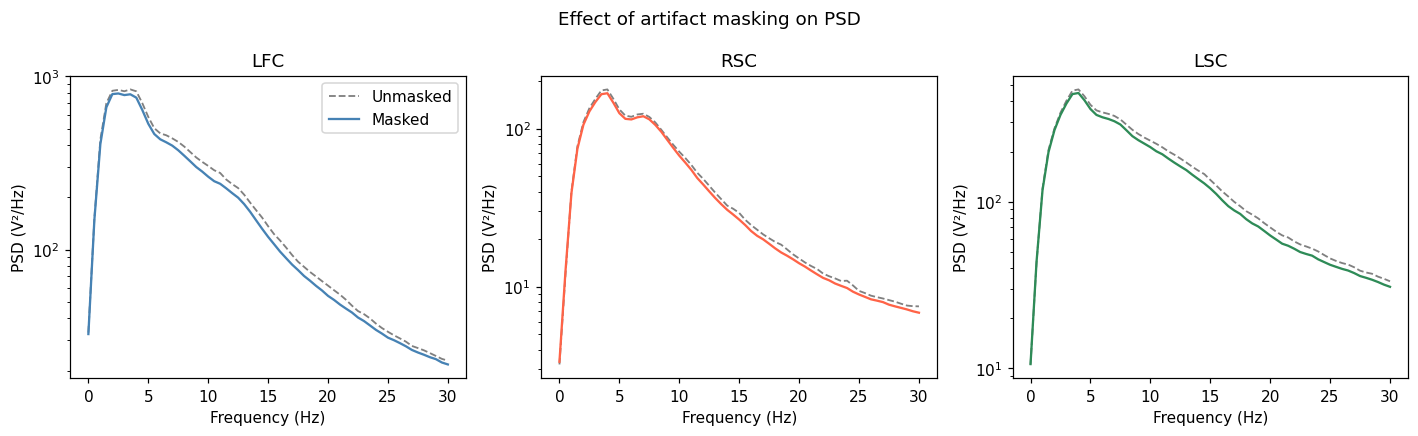

In [38]:
combined_mask = comm_mask & sd_mask  # True = clean sample

with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0, 1, 2]
    pro = producer(reader, chunksize=int(30e5), axis=-1)
    masked_pro = producer(pro, chunksize=int(30e5), axis=-1, mask=combined_mask)
    cnt_m, freqs, psds_masked = psd(masked_pro, fs=FS, resolution=0.5)

# Overlay comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
for i, ax in enumerate(axes):
    ax.semilogy(freqs[freq_mask], psds_raw[i, freq_mask],    color='gray',      lw=1.2, ls='--', label='Unmasked')
    ax.semilogy(freqs[freq_mask], psds_masked[i, freq_mask], color=colors[i],   lw=1.5,          label='Masked')
    ax.set_title(CH_NAMES[i])
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (V²/Hz)')
axes[0].legend()
fig.suptitle('Effect of artifact masking on PSD')
plt.tight_layout()
plt.show()

---
## 5. State-specific PSDs (wake / NREM / REM)

PSDs look very different between sleep states. We use the Spindle-generated CSV
to restrict which samples enter the Welch average.

In [39]:
# Build state masks from Spindle CSV
state_labels = {'wake': ['w'], 'nrem': ['n'], 'rem': ['r']}
state_masks  = {
    name: masking.state(STATE_CSV, codes, fs=FS, winsize=4)
    for name, codes in state_labels.items()
}

for name, m in state_masks.items():
    hrs = m.sum() / FS / 3600
    print(f"{name:>5}: {m.mean()*100:5.1f}% of recording  ({hrs:.2f} h)")

 wake:  42.8% of recording  (2.57 h)
 nrem:  46.4% of recording  (2.79 h)
  rem:  10.8% of recording  (0.65 h)


In [42]:
state_masks['wake'][0:20]

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True])

In [43]:
state_psds = {}

with edf.Reader(EDF_PATH) as reader:
    reader.channels = [0, 1, 2]
    pro_base = producer(reader, chunksize=int(30e5), axis=-1)

    for state, s_mask in state_masks.items():
        # combine artifact mask with state mask
        final_mask = combined_mask & s_mask
        if state == 'wake':
            final_mask &= sd_mask  # SD threshold applied only during wake

        if not np.any(final_mask):
            print(f"  {state}: no clean samples — skipping")
            continue

        masked_pro = producer(pro_base, chunksize=int(30e5), axis=-1, mask=final_mask)
        cnt_s, freqs, p = psd(masked_pro, fs=FS, resolution=0.5)
        state_psds[state] = p
        print(f"  {state}: {cnt_s} windows used")

  wake: 9061 windows used
  nrem: 9831 windows used
  rem: 2310 windows used


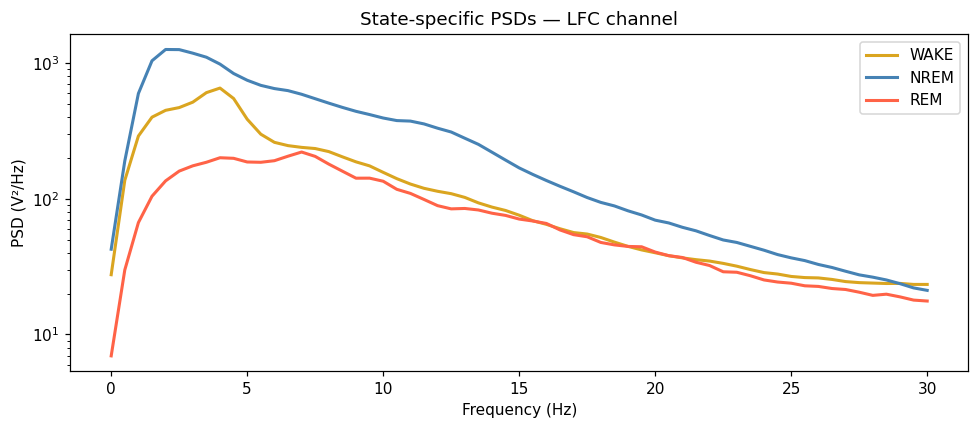

In [46]:
state_colors = {'wake': 'goldenrod', 'nrem': 'steelblue', 'rem': 'tomato'}
CH_IDX = 0  # plot LFC channel; change to 1 for RSC etc.

fig, ax = plt.subplots(figsize=(9, 4))
for state, p in state_psds.items():
    ax.semilogy(freqs[freq_mask], p[CH_IDX, freq_mask],
                label=state.upper(), color=state_colors[state], lw=2)

ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('PSD (V²/Hz)')
ax.set_title(f'State-specific PSDs — {CH_NAMES[CH_IDX]} channel')
ax.legend()
plt.tight_layout()
plt.show()

**What to look for:**
- **NREM**: large delta peak (0.5–4 Hz) — slow oscillations of deep sleep
- **REM**: theta peak (4–8 Hz) in RSC/hippocampal channels; low EMG
- **Wake**: flatter spectrum; higher beta/gamma; large EMG signal

---
## 6. Load results from psds_channel_merged.pkl

After running the full pipeline through the GUI, results are stored in `psd/psds_channel_merged.pkl`
as a list of dicts (one per animal × state combination).

In [15]:
with open(MERGED_PKL, 'rb') as f:
    records = pickle.load(f)

# Each record is a dict with these keys:
print("Keys in each record:")
print(list(records[0].keys()))
print(f"\nTotal records: {len(records)}")

# Unique animals and states
animals = sorted({Path(r['path']).stem.split('_')[0] for r in records})
states  = sorted({r['behavior'] for r in records})
print(f"Animals ({len(animals)}): {animals}")
print(f"States            : {states}")

Keys in each record:
['path', 'channels', 'behavior', 'n_estimates', 'spindle_out_frac', 'comm_out_frac', 'sd_out_frac', 'swd_out_frac', 'used_swd', 'used_drink', 'freqs', 'psd', 'params', 'source_combo']

Total records: 9
Animals (3): ['ASR05', 'ASR06', 'ASR07']
States            : [('threshold', 'nrem'), ('threshold', 'rem'), ('threshold', 'wake')]


In [19]:
# Build a tidy DataFrame of band powers for easy exploration
BANDS = {
    'delta': (0.5, 4),
    'theta': (4,   8),
    'alpha': (8,  13),
    'beta':  (13, 30),
}

def band_power(freqs, psd_arr, lo, hi):
    """Integrate PSD between lo and hi Hz using the trapezoidal rule."""
    mask = (freqs >= lo) & (freqs <= hi)
    return np.trapz(psd_arr[mask], freqs[mask])

rows = []
for r in records:
    animal  = Path(r['path']).stem.split('_')[0]
    state   = r['behavior']
    freqs_r = np.array(r['freqs'])
    psd_arr = np.array(r['psd'])   # shape: channels × freqs
    freq_m  = freqs_r <= 30

    for ch_idx, ch_name in enumerate(CH_NAMES[:psd_arr.shape[0]]):
        row = dict(animal=animal, state=state, channel=ch_name)
        for band, (lo, hi) in BANDS.items():
            row[band] = band_power(freqs_r, psd_arr[ch_idx], lo, hi)
        rows.append(row)

df = pd.DataFrame(rows)
df.head(20)

,animal,state,channel,delta,theta,alpha,beta
0,ASR05,"(threshold, wake)",LFC,1147.581385,1143.202934,660.265727,680.161174
1,ASR05,"(threshold, wake)",RSC,256.516540,392.595468,223.310448,233.443125
2,ASR05,"(threshold, wake)",LSC,636.375171,877.896606,569.404221,791.152163
3,ASR05,"(threshold, nrem)",LFC,3379.909289,2887.225310,2182.614889,1568.337901
4,ASR05,"(threshold, nrem)",RSC,503.063222,599.310954,425.021180,283.762873
5,ASR05,"(threshold, nrem)",LSC,1353.659795,1873.520754,1584.614970,1647.382303
6,ASR05,"(threshold, rem)",LFC,484.782194,876.442318,647.197327,738.947037
7,ASR05,"(threshold, rem)",RSC,160.095610,391.018028,220.237202,149.822917
8,ASR05,"(threshold, rem)",LSC,724.160030,1187.144218,866.801950,973.093236
9,ASR07,"(threshold, wake)",LFC,495.345598,678.431508,463.423046,633.262893


---
## 7. Group-level PSD plots

Plot mean ± SEM across all animals for each state.

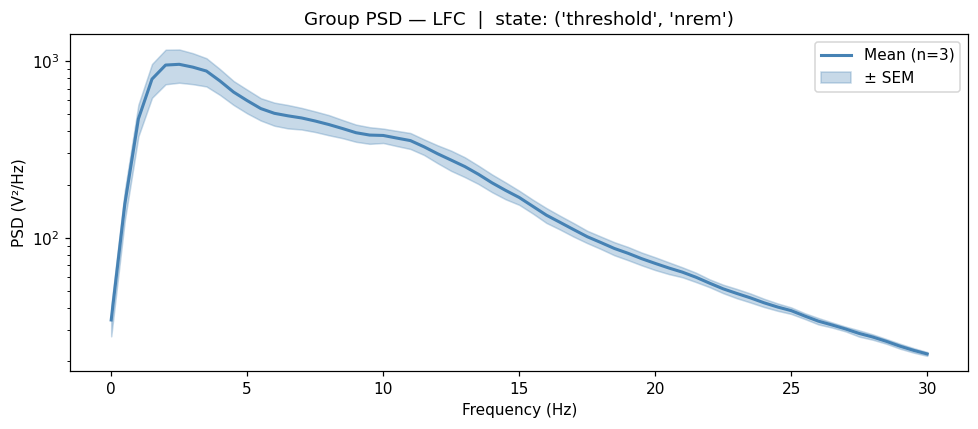

In [22]:
def collect_psds(records, state_filter, ch_idx=0):
    """Return array of shape (n_animals, n_freqs) for a given state and channel."""
    matched = [r for r in records if r['behavior'] == state_filter]
    if not matched:
        return None, None
    freqs_r = np.array(matched[0]['freqs'])
    mat = np.array([np.array(r['psd'])[ch_idx] for r in matched])
    return freqs_r, mat

# Pick a state to visualise (edit as needed)
TARGET_STATE = ('threshold', 'nrem')  # must match the tuple stored in behavior field
CH_IDX = 0

freqs_r, mat = collect_psds(records, TARGET_STATE, CH_IDX)

if mat is not None:
    freq_m = freqs_r <= 30
    mean_p = mat[:, freq_m].mean(axis=0)
    sem_p  = mat[:, freq_m].std(axis=0) / np.sqrt(mat.shape[0])

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.semilogy(freqs_r[freq_m], mean_p, color='steelblue', lw=2, label=f'Mean (n={mat.shape[0]})')
    ax.fill_between(freqs_r[freq_m],
                    np.clip(mean_p - sem_p, 1e-20, None),
                    mean_p + sem_p,
                    alpha=0.3, color='steelblue', label='± SEM')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (V²/Hz)')
    ax.set_title(f'Group PSD — {CH_NAMES[CH_IDX]}  |  state: {TARGET_STATE}')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"No records found matching state '{TARGET_STATE}'. "
          f"Available states: {sorted({r['behavior'] for r in records})}")

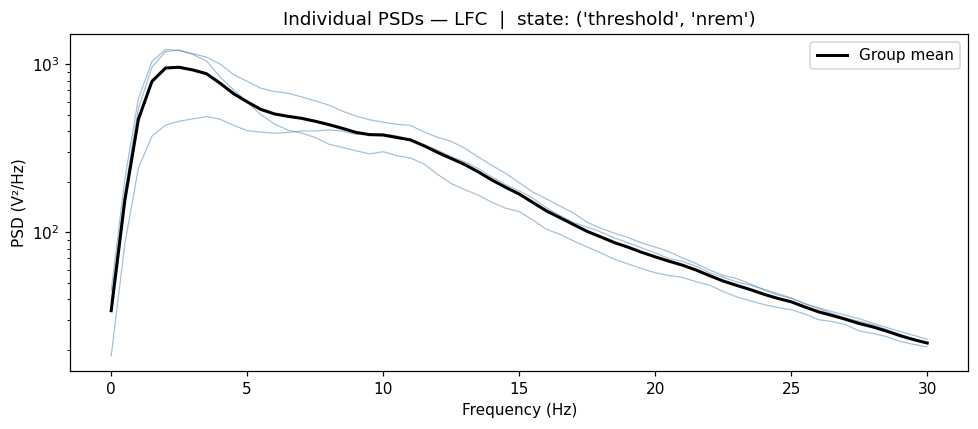

In [23]:
# Individual animal traces (spaghetti plot) — useful for spotting outliers
if mat is not None:
    fig, ax = plt.subplots(figsize=(9, 4))
    for i, row in enumerate(mat):
        ax.semilogy(freqs_r[freq_m], row[freq_m], lw=0.8, alpha=0.5, color='steelblue')
    ax.semilogy(freqs_r[freq_m], mean_p, color='black', lw=2, label='Group mean')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (V²/Hz)')
    ax.set_title(f'Individual PSDs — {CH_NAMES[CH_IDX]}  |  state: {TARGET_STATE}')
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## 8. Band power summary

Collapse the full spectrum down to canonical EEG bands for statistics.

In [24]:
# Mean band power per state, one channel
TARGET_CH = 'LFC'
summary = (
    df[df['channel'] == TARGET_CH]
    .groupby('state')[list(BANDS.keys())]
    .agg(['mean', 'sem'])
)
summary

delta                    theta              \
                          mean         sem         mean         sem   
state                                                                 
(threshold, nrem)  2720.170294  673.013673  2170.644653  373.870137   
(threshold, rem)    420.865872   60.596188   759.668526   74.580422   
(threshold, wake)  1129.010599  360.605302  1016.747471  170.945189   

                         alpha                     beta              
                          mean         sem         mean         sem  
state                                                                
(threshold, nrem)  1769.317145  238.488108  1365.520993  140.675294  
(threshold, rem)    579.471568   33.865040   694.970917   22.512416  
(threshold, wake)   608.513296   73.531674   676.933568   24.335116

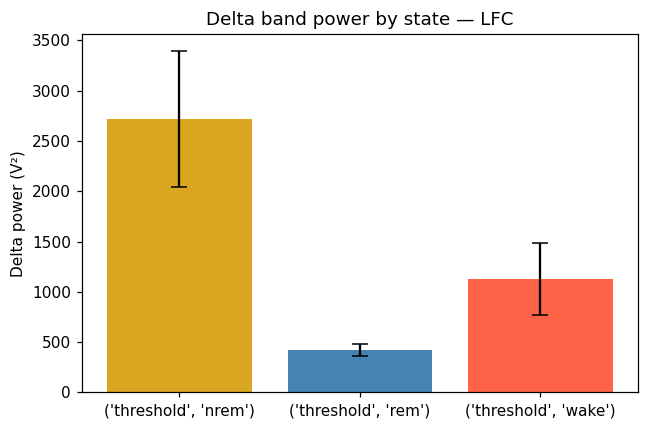

In [25]:
# Bar chart: delta power across states
sub = df[(df['channel'] == TARGET_CH)].groupby('state')['delta'].agg(['mean', 'sem']).reset_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(sub['state'].astype(str), sub['mean'], yerr=sub['sem'],
       capsize=5, color=['goldenrod', 'steelblue', 'tomato'][:len(sub)])
ax.set_ylabel('Delta power (V²)')
ax.set_title(f'Delta band power by state — {TARGET_CH}')
plt.tight_layout()
plt.show()